In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Cambios que aplica a una imagen antes de pasarla a una red neuronal
# Compose para aplicarlas a todas
#Ejemplo de 1 píxel:
#255 (blanco)  →  1.0  →  1.0
#128 (gris)    →  0.5  →  0.0
#0 (negro)     →  0.0  → -1.0
transform = transforms.Compose([
    transforms.ToTensor(), # Convierte los valores de un pixel que es 255 a numeros entre 0 y 1
    transforms.Normalize((0.5,), (0.5,)) # Normaliza los valores para que se encuentren entre -1 y 1
])

# Descargar y cargar datos de entrenamiento
trainset = datasets.MNIST('MNIST_data/', download=True, train=True, transform=transform) 
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

# Descargar y cargar datos de prueba
testset = datasets.MNIST('MNIST_data/', download=True, train=False, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=True)

print("Dataset MNIST cargado correctamente")
print(f"Datos de entrenamiento: {len(trainset)} imágenes")
print(f"Datos de prueba: {len(testset)} imágenes")

Dataset MNIST cargado correctamente
Datos de entrenamiento: 60000 imágenes
Datos de prueba: 10000 imágenes


In [2]:
# Ahora aqui lo que hacemos es crear una red neuronal simple

class Network(nn.Module):
    def __init__(self):
        super().__init__()
        # Definiendo las capas
        self.fc1 = nn.Linear(784, 128)   # Entrada: 28x28=784, Salida: 128 o sea esa salida son las neuronas
        self.fc2 = nn.Linear(128, 64)    # Entrada: 128, Salida: 64
        self.fc3 = nn.Linear(64, 10)     # Entrada: 64, Salida: 10 (dígitos 0-9)
        
    def forward(self, x):
        '''Pase hacia adelante a través de la red'''
        # Aplanar la imagen (28x28 -> 784) o sea que la convierte en una sola dimension
        x = x.view(x.shape[0], -1)
        
        x = self.fc1(x)          # Capa 1
        x = F.relu(x)            # Activación ReLU
        x = self.fc2(x)          # Capa 2
        x = F.relu(x)            # Activación ReLU
        x = self.fc3(x)          # Capa 3 (salida)
        x = F.softmax(x, dim=1)  # Softmax para probabilidades
        
        return x

# Crear la red
model = Network()
print("Arquitectura de la red:")
print(model)
print(f"\nTotal de parámetros: {sum(p.numel() for p in model.parameters())}")

Arquitectura de la red:
Network(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)

Total de parámetros: 109386


In [4]:
# Calcular precisión antes de entrenar
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Network().to(device) 
model.eval()

correct = 0
total = 0
with torch.no_grad():
    for images, labels in testloader:
        images = images.resize_(images.size()[0], 784).to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy_mnist_sin_entrenar = 100 * correct / total
print(f"Precisión SIN ENTRENAR (MNIST): {accuracy_mnist_sin_entrenar:.2f}%")

Precisión SIN ENTRENAR (MNIST): 10.09%


Tamaño del lote: torch.Size([64, 1, 28, 28])
Etiquetas: tensor([2, 4, 2, 4, 1, 5, 5, 7, 2, 1])

Salida de la red (probabilidades):
tensor([[0.1137, 0.1049, 0.0889, 0.1043, 0.0693, 0.0909, 0.0958, 0.1043, 0.0907,
         0.1374]], grad_fn=<SoftmaxBackward0>)

Predicción: 9
Verdadero: 2



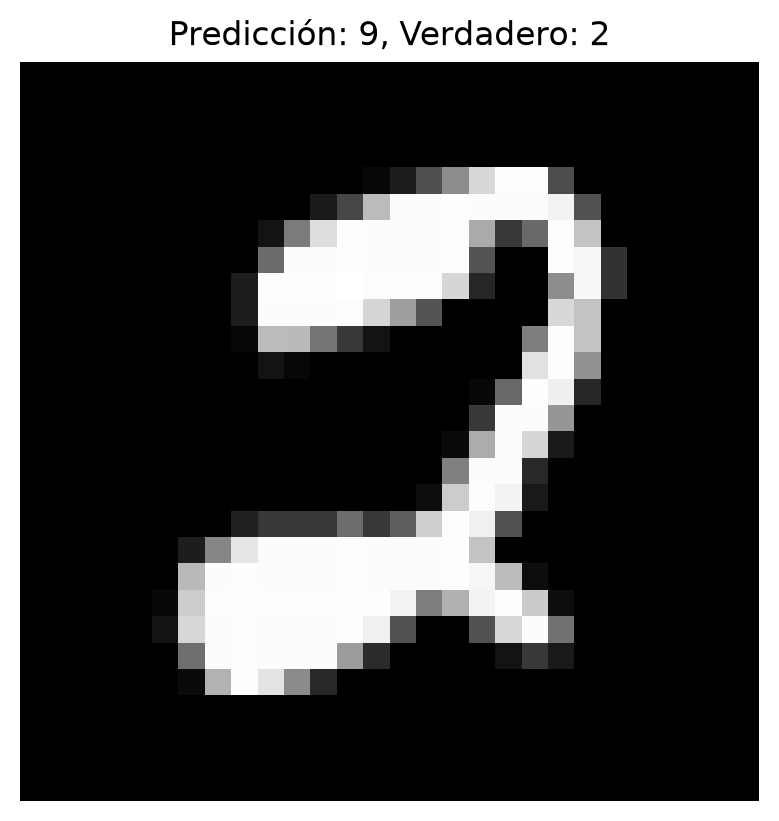

In [5]:
# Ahora hacemos que pase para adelante o sea que pase una imagen capa por capa

# Obtener un lote de imágenes del dataset
dataiter = iter(trainloader) # Crea un iterador para que pueda recorrer
images, labels = next(dataiter) # Obtiene el primer lote, nos manda la matriz de la imagen y el valor verdadero

print(f"Tamaño del lote: {images.shape}")
print(f"Etiquetas: {labels[:10]}")  # Primeras 10 etiquetas
print()

# Hacer un pase hacia adelante con la primera imagen
output = model(images[0].unsqueeze(0))  # Añadir dimensión de batch

print("Salida de la red (probabilidades):")
print(output)
print()

# Obtener la predicción (el dígito con mayor probabilidad)
pred = torch.argmax(output, dim=1)
print(f"Predicción: {pred.item()}")
print(f"Verdadero: {labels[0].item()}")
print()

# Visualizar la imagen
plt.imshow(images[0].numpy().squeeze(), cmap='gray')
plt.title(f"Predicción: {pred.item()}, Verdadero: {labels[0].item()}")
plt.axis('off')
plt.show()